# 13 – Uranus (stage 11: planets)

**What:** A colour close-up of Uranus from NIRCam data of programme 6379 (observation o002, six wide-band filters). Same workflow as notebook 12 (Neptune), but with all target-specific values collected in **one parameter cell** – a test of how well the planet workflow carries over.

**Why:** Neptune showed what is special about planets: a moving target (align on the planet, not on stars), a small disk on a large field (close-up grid at the short-wavelength pixel scale), saturated bright features, and colours that mix to the average hue when the disk is similarly bright in all filters. Uranus has more filters (six instead of four, from 0.7 to 4.4 µm), is larger on the sky (≈ 3.7″ vs. ≈ 2.3″) and also has rings.

**Steps (with checkpoints):** 1 Data (*check size before download*) · 2 Moving target in the header · 3 First look (*choose the sharp filter for comparisons*) · 4 Stripes (*2-D background safe?*) · 5 Alignment on the planet · 6 Bad pixels and saturated features · 7 Background and stretch (*stretch strength*) · 8 Colour (*variant*) · 9 Export

**Result:** Two colour close-ups of Uranus and its rings (20″ × 20″, 652 × 652 px at 0.031″/px, north up), in `output/`: **A_chromatic** (hues by wavelength, golden rings) and **D_silver_rings** (aesthetic choice: turquoise disk, F356W laid over as white light → silver rings). Five filters F115W–F444W; F070W left out (disk saturated). Three exposure groups (≈ 40 min apart, 0.24″ planet motion each) aligned on the planet. All parameters in `params/uranus.json`.

## 1. Data

All target-specific settings are in the first cell. Run with `DOWNLOAD = False` first and check the list and the total size; then set it to `True`.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from astropy.visualization import AsinhStretch, PercentileInterval, ImageNormalize
from astropipe import bands, clean, color, export, mast, registration, stretch
from astropipe.run import assess_field

# ---- target-specific parameters ------------------------------------------------
TARGET = "Uranus"
PROGRAM, OBS = 6379, "jw06379-o002_t001_"   # programme and observation prefix of the i2d files
FIELD_ARCSEC = 20.0                         # close-up field; Uranus ≈ 3.7", rings out to ≈ 2.1 planet radii (to be checked)
SHARP = None                                # filter for comparisons/luminance – set after step 3 (None = sharpest SW filter)
DOWNLOAD = True                            # first check the list below
EXCLUDE = ["F070W"]                         # disk saturated in F070W (step 5) – not used for the colour image
SHARP = "F150W"                             # chosen after step 3: sharp rings and disk structure
# ----------------------------------------------------------------------------------

ROOT = Path("..")
RAW = ROOT / f"data/{TARGET.lower()}_{PROGRAM}_nircam"
WORK = ROOT / f"data/{TARGET.lower()}_nb"
WORK.mkdir(parents=True, exist_ok=True)


def show(ax, img, title="", pct=99.5, a=0.02):
    """Quick-look display: percentile limits + asinh."""
    norm = ImageNormalize(img, interval=PercentileInterval(pct), stretch=AsinhStretch(a))
    ax.imshow(img, origin="lower", cmap="gray", norm=norm)
    ax.set_title(title)
    ax.axis("off")


def cut(img, cy, cx, half):
    """Square cutout of +-half pixels around (cy, cx)."""
    cy, cx = int(round(cy)), int(round(cx))
    return img[max(cy - half, 0):cy + half, max(cx - half, 0):cx + half]


obs, i2d = mast.find_i2d(PROGRAM)
i2d = i2d[[n.startswith(OBS) for n in i2d["productFilename"]]]
for name, size in zip(i2d["productFilename"], i2d["size"]):
    print(f"{name:55s} {size / 1e6:8.1f} MB")
print(f"{len(i2d)} files, {mast.total_size_gb(i2d):.2f} GB")

if DOWNLOAD:
    mast.download(i2d, RAW, max_gb=4.0)
FILES = {bands.band_from_header(fits.getheader(f, 0)): f for f in sorted(RAW.glob(f"{OBS}*_i2d.fits"))}
FILES = {b: FILES[b] for b in bands.sort_bands(FILES)}
FILES

jw06379-o002_t001_nircam_clear-f070w_i2d.fits              119.1 MB
jw06379-o002_t001_nircam_clear-f356w_i2d.fits              122.4 MB
jw06379-o002_t001_nircam_clear-f115w_i2d.fits              119.1 MB
jw06379-o002_t001_nircam_clear-f444w_i2d.fits              122.4 MB
jw06379-o002_t001_nircam_clear-f150w_i2d.fits              119.1 MB
jw06379-o002_t001_nircam_clear-f277w_i2d.fits              122.4 MB
6 files, 0.72 GB
6 of 6 files already present, 0 to download (0.00 GB)


{'F070W': PosixPath('../data/uranus_6379_nircam/jw06379-o002_t001_nircam_clear-f070w_i2d.fits'),
 'F115W': PosixPath('../data/uranus_6379_nircam/jw06379-o002_t001_nircam_clear-f115w_i2d.fits'),
 'F150W': PosixPath('../data/uranus_6379_nircam/jw06379-o002_t001_nircam_clear-f150w_i2d.fits'),
 'F277W': PosixPath('../data/uranus_6379_nircam/jw06379-o002_t001_nircam_clear-f277w_i2d.fits'),
 'F356W': PosixPath('../data/uranus_6379_nircam/jw06379-o002_t001_nircam_clear-f356w_i2d.fits'),
 'F444W': PosixPath('../data/uranus_6379_nircam/jw06379-o002_t001_nircam_clear-f444w_i2d.fits')}

## 2. Moving target in the header

`TARGTYPE = MOVING`; `MT_AVRA` / `MT_AVDEC` (SCI header) = mean position of the target during the exposure. Short- and long-wavelength filters are exposed in pairs at the same time; the planet moves between the pairs.

In [2]:
rows = {}
for b, f in FILES.items():
    h0, h1 = fits.getheader(f, 0), fits.getheader(f, extname="SCI")
    rows[b] = dict(date=h0["DATE-BEG"][:10], start=h0["DATE-BEG"][11:19], end=h0["DATE-END"][11:19],
                   targtype=h0["TARGTYPE"], mt_ra=h1["MT_AVRA"], mt_dec=h1["MT_AVDEC"],
                   pix=float(registration.pixel_scale_arcsec(WCS(h1))[0]))

ref = next(iter(rows))
DATE = rows[ref]["date"]
for b, r in rows.items():
    dra = (r["mt_ra"] - rows[ref]["mt_ra"]) * 3600 * np.cos(np.radians(r["mt_dec"]))
    ddec = (r["mt_dec"] - rows[ref]["mt_dec"]) * 3600
    d = np.hypot(dra, ddec)
    print(f"{b}: {r['date']} {r['start']}-{r['end']} UTC  {r['targtype']}  pixel {r['pix']:.4f}\"  "
          f"planet position vs {ref}: {d:.3f}\" (= {d / 0.031:.1f} px at 0.031\")")

F070W: 2025-02-02 09:12:55-09:51:13 UTC  MOVING  pixel 0.0307"  planet position vs F070W: 0.000" (= 0.0 px at 0.031")
F115W: 2025-02-02 08:32:50-09:07:33 UTC  MOVING  pixel 0.0307"  planet position vs F070W: 0.243" (= 7.8 px at 0.031")
F150W: 2025-02-02 07:49:10-08:27:28 UTC  MOVING  pixel 0.0307"  planet position vs F070W: 0.483" (= 15.6 px at 0.031")
F277W: 2025-02-02 09:12:55-09:51:13 UTC  MOVING  pixel 0.0625"  planet position vs F070W: 0.000" (= 0.0 px at 0.031")
F356W: 2025-02-02 07:49:10-08:27:28 UTC  MOVING  pixel 0.0625"  planet position vs F070W: 0.483" (= 15.6 px at 0.031")
F444W: 2025-02-02 08:32:50-09:07:33 UTC  MOVING  pixel 0.0625"  planet position vs F070W: 0.243" (= 7.8 px at 0.031")


## 3. First look

Each filter in its own pixel grid, centred on the planet's disk. Top: 40″ (rings, moons, background). Bottom: the close-up field with a strong stretch.

**Checkpoint:** which filter shows the rings and cloud features most sharply? → set `SHARP` in the parameter cell (used for the stripe comparison, the stretch comparison and as luminance).

SHARP = F150W


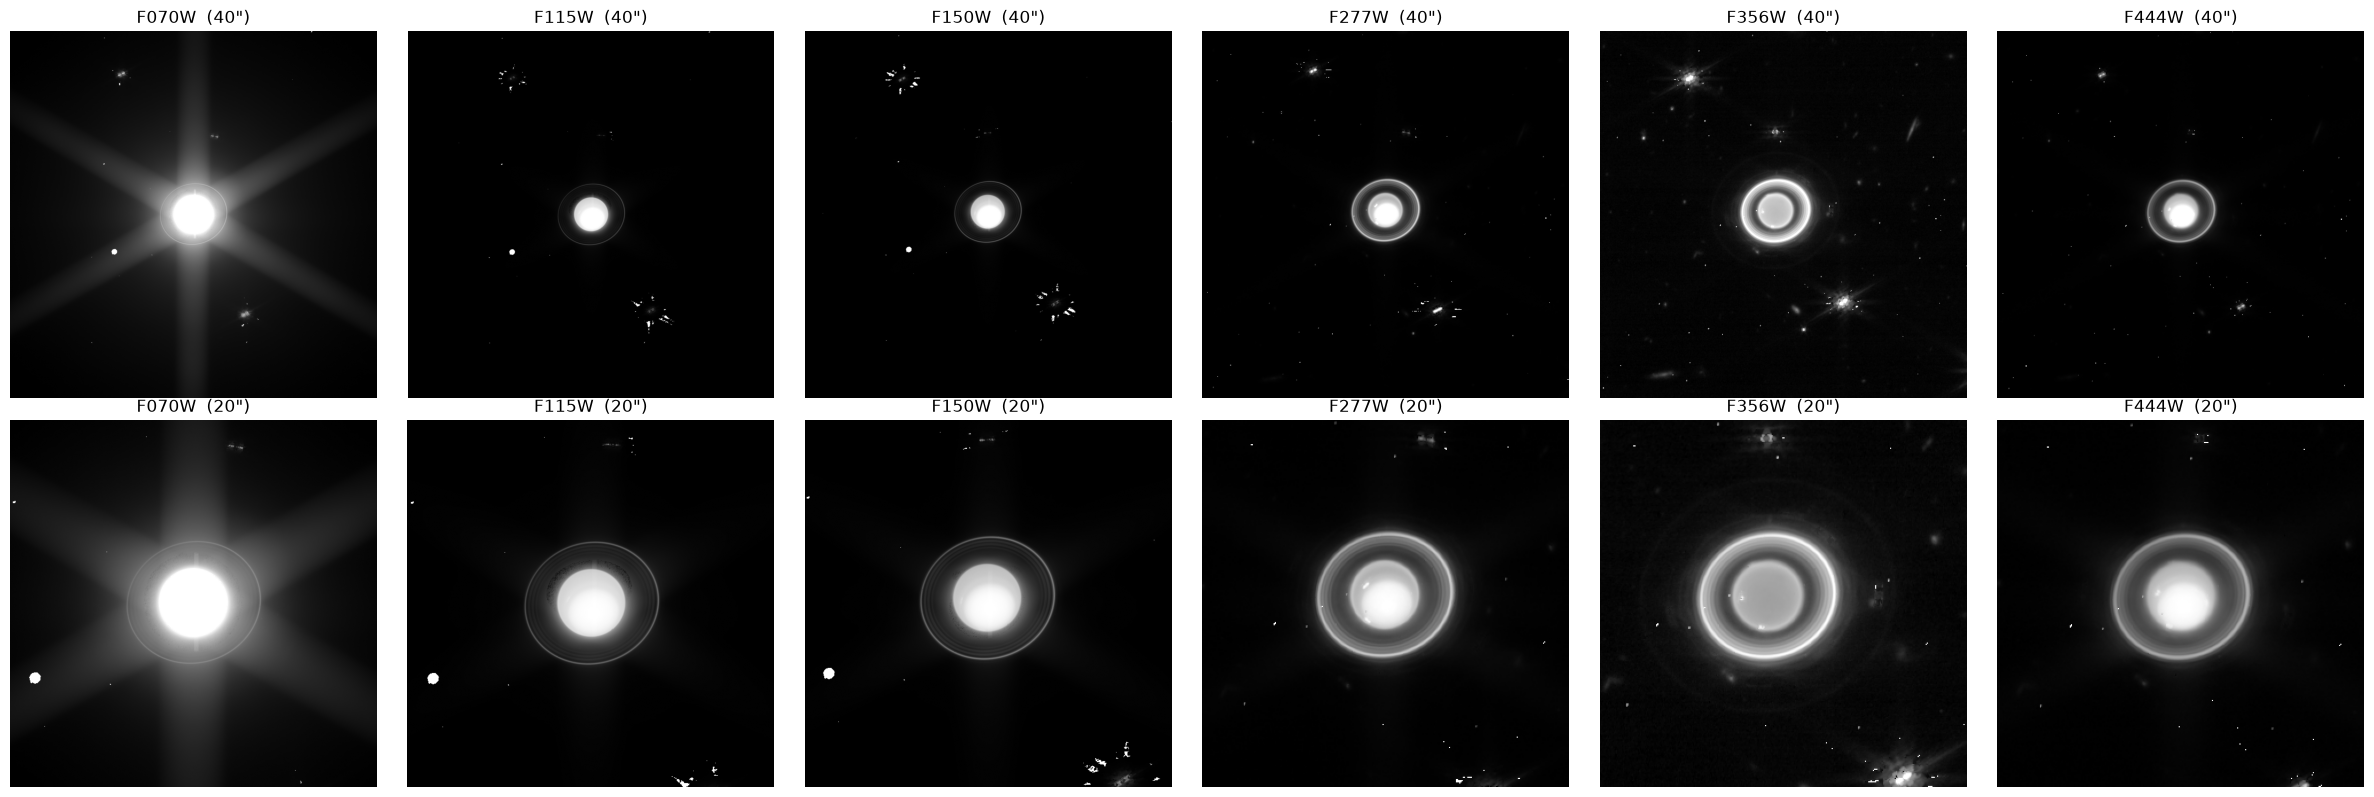

In [3]:
raw = {b: fits.getdata(f, extname="SCI").astype(np.float32) for b, f in FILES.items()}
pix = {b: rows[b]["pix"] for b in raw}
cen_raw = {b: registration.disk_centroid(img) for b, img in raw.items()}

nb_ = len(raw)
fig, axes = plt.subplots(2, nb_, figsize=(4 * nb_, 8))
for i, b in enumerate(raw):
    cy, cx = cen_raw[b]
    show(axes[0, i], cut(raw[b], cy, cx, int(20 / pix[b])), f"{b}  (40\")")
    show(axes[1, i], cut(raw[b], cy, cx, int(FIELD_ARCSEC / 2 / pix[b])), f"{b}  ({FIELD_ARCSEC:.0f}\")",
         pct=99.9, a=0.005)
plt.tight_layout()

if SHARP is None:                       # default: longest-wavelength filter with the fine (SW) pixel scale
    SHARP = [b for b in raw if pix[b] < 0.04][-1]
print("SHARP =", SHARP)

## 4. Stripes

Same check as for Neptune: automatic measurement, then row destriping on empty sky without high-pass and optionally a 2-D background (128-px cells). The bottom row shows what each step removed – it must not contain rings or limb structure.

In [4]:
field = assess_field(FILES)
print("empty field:", field["empty_field"])

[18:56:30] field type: empty (compact sources)
[18:56:30] F070W: structure 4.2 sigma, sky 0.83, stripes rows 1.00 / columns 1.04 -> sky (columns), 2-D bg 128
[18:56:30] F115W: structure 4.0 sigma, sky 0.75, stripes rows 0.93 / columns 0.82 -> sky (rows), 2-D bg 128
[18:56:30] F150W: structure 2.9 sigma, sky 0.71, stripes rows 0.83 / columns 0.64 -> sky (rows), 2-D bg 128
[18:56:30] F277W: structure 0.7 sigma, sky 0.47, stripes rows 0.31 / columns 0.21 -> sky (rows), 2-D bg 128
[18:56:30] F356W: structure 0.5 sigma, sky 0.43, stripes rows 0.29 / columns 0.18 -> sky (rows), 2-D bg 128
[18:56:30] F444W: structure 0.5 sigma, sky 0.47, stripes rows 0.27 / columns 0.16 -> sky (rows), 2-D bg 128
empty field: True


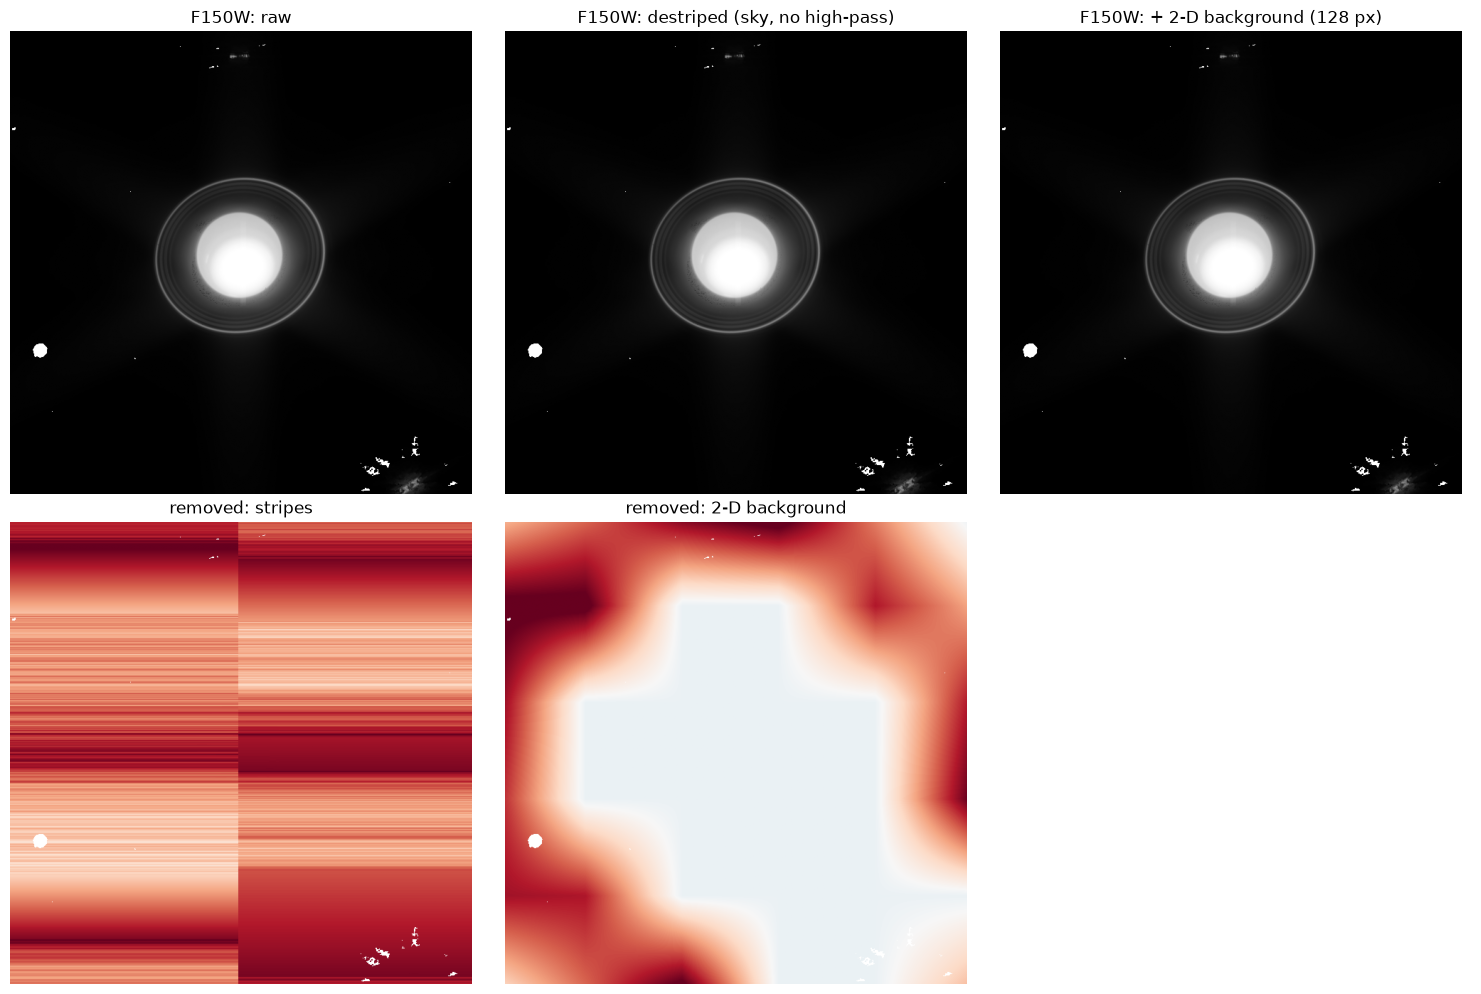

In [5]:
img = raw[SHARP]
sky, _, _ = clean.destripe(img, "rows", smooth=0, segment=512)
sky_bg, model = clean.subtract_background_2d(sky, cell=128)

cy, cx = cen_raw[SHARP]
h = int(FIELD_ARCSEC / 2 / pix[SHARP])
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, im, t in zip(axes[0], [img, sky, sky_bg],
                     ["raw", "destriped (sky, no high-pass)", "+ 2-D background (128 px)"]):
    show(ax, cut(im, cy, cx, h), f"{SHARP}: {t}", pct=99.0, a=0.005)
for ax, im, t in zip(axes[1], [img - sky, sky - sky_bg], ["removed: stripes", "removed: 2-D background"]):
    c = cut(im, cy, cx, h)
    s = np.nanpercentile(np.abs(c), 99)
    ax.imshow(c, origin="lower", cmap="RdBu_r", vmin=-s, vmax=s)
    ax.set_title(t)
    ax.axis("off")
axes[1, 2].axis("off")
plt.tight_layout()

**Checkpoint:** rings or limb in "removed: 2-D background"? If yes → `USE_BG2D = False`.

In [6]:
USE_BG2D = False

cleaned = {}
for b, f in FILES.items():
    out, _, _ = clean.destripe(raw[b], "rows", smooth=0, segment=512)
    if USE_BG2D:
        out, _ = clean.subtract_background_2d(out, cell=128)
    dest = WORK / "cleaned" / f.name.replace("_i2d", "_clean_i2d")
    clean.write_cleaned_i2d(f, dest, out, f"13_uranus: destripe sky smooth=0 segment=512, bg2d={USE_BG2D}")
    cleaned[b] = dest
    print(b, "->", dest.name)

F070W -> jw06379-o002_t001_nircam_clear-f070w_clean_i2d.fits
F115W -> jw06379-o002_t001_nircam_clear-f115w_clean_i2d.fits
F150W -> jw06379-o002_t001_nircam_clear-f150w_clean_i2d.fits
F277W -> jw06379-o002_t001_nircam_clear-f277w_clean_i2d.fits
F356W -> jw06379-o002_t001_nircam_clear-f356w_clean_i2d.fits
F444W -> jw06379-o002_t001_nircam_clear-f444w_clean_i2d.fits


## 5. Alignment on the planet – close-up grid

WCS of each image shifted by the difference of the `MT_AV` positions; close-up grid (`FIELD_ARCSEC`) north up, centred on the planet, at the finest pixel scale of the data (short-wavelength filters); long-wavelength filters are upsampled ×2 (no new detail).

**Check:** geometric disk centre per filter (threshold from the disk of the longest-wavelength filter, no rings) – expected well below 1 px apart. Overlay: first filter (magenta) vs. last filter (green).

In [7]:
offs = registration.moving_target_offsets(cleaned)
shifted = {}
for b, f in cleaned.items():
    dra, ddec = offs[b]
    shifted[b] = registration.write_shifted_i2d(f, WORK / "mt" / f.name.replace(".fits", "_mt.fits"), dra, ddec)
    print(f"{b}: WCS shifted by ({dra * 3600:+.3f}\", {ddec * 3600:+.3f}\") in (RA, Dec)")

RES = min(pix.values())
ra0, dec0 = rows[ref]["mt_ra"], rows[ref]["mt_dec"]
n = int(round(FIELD_ARCSEC / RES))
wcs_out = WCS(naxis=2)
wcs_out.wcs.ctype = ["RA---TAN", "DEC--TAN"]
wcs_out.wcs.crval = [ra0, dec0]
wcs_out.wcs.crpix = [(n + 1) / 2, (n + 1) / 2]
wcs_out.wcs.cdelt = [-RES / 3600, RES / 3600]
shape_out = (n, n)

reproj = registration.reproject_all(shifted, wcs_out, shape_out, WORK / "reproj_zoom", f"{TARGET.lower()}_zoom")
imgs = {b: fits.getdata(p).astype(np.float32) for b, p in reproj.items() if b not in EXCLUDE}
print("grid", shape_out, f"at {RES:.4f}\"/px")

F070W: WCS shifted by (+0.000", +0.000") in (RA, Dec)
F115W: WCS shifted by (+0.243", +0.075") in (RA, Dec)
F150W: WCS shifted by (+0.484", +0.149") in (RA, Dec)
F277W: WCS shifted by (+0.000", +0.000") in (RA, Dec)
F356W: WCS shifted by (+0.484", +0.149") in (RA, Dec)
F444W: WCS shifted by (+0.243", +0.075") in (RA, Dec)
F070W   outdated (made from jw06379-o002_t001_nircam_clear-f070w_clean_i2d_mt.fits) -> reprojecting
F070W      0.6 s -> uranus_zoom_f070w_reproj.fits
F115W   outdated (made from jw06379-o002_t001_nircam_clear-f115w_clean_i2d_mt.fits) -> reprojecting
F115W      0.6 s -> uranus_zoom_f115w_reproj.fits
F150W   outdated (made from jw06379-o002_t001_nircam_clear-f150w_clean_i2d_mt.fits) -> reprojecting
F150W      0.6 s -> uranus_zoom_f150w_reproj.fits
F277W   outdated (made from jw06379-o002_t001_nircam_clear-f277w_clean_i2d_mt.fits) -> reprojecting
F277W      0.5 s -> uranus_zoom_f277w_reproj.fits
F356W   outdated (made from jw06379-o002_t001_nircam_clear-f356w_clean_i2d_m

grid centre (325.5, 325.5)
F115W: disk centre (326.5, 325.7), offset vs F115W 0.00 px
F150W: disk centre (326.4, 331.4), offset vs F115W 5.62 px
F277W: disk centre (325.3, 338.0), offset vs F115W 12.28 px
F356W: disk centre (328.1, 326.2), offset vs F115W 1.73 px
F444W: disk centre (326.0, 335.4), offset vs F115W 9.65 px


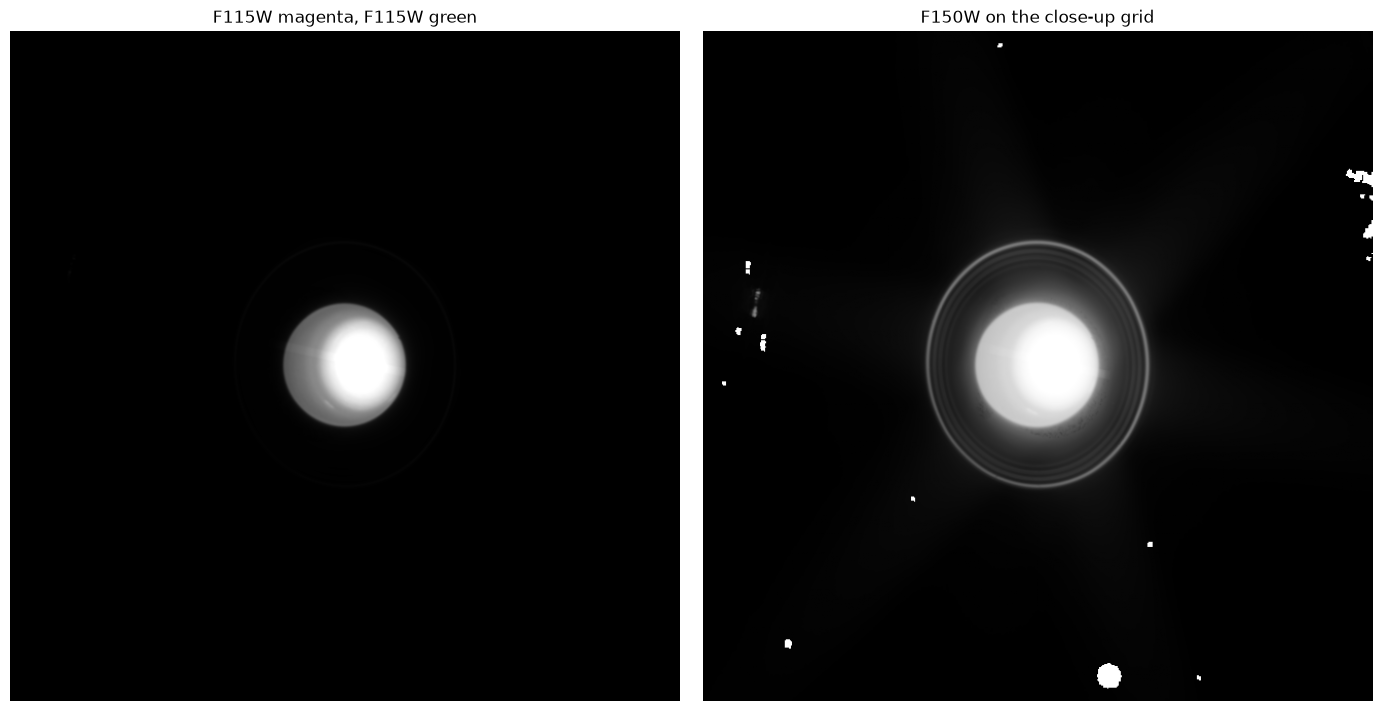

In [8]:
REF = "F115W"      # full, evenly lit disk; in F150W/F277W/F444W mainly the bright polar region shows
ref_disk = registration.disk_mask(imgs[REF])
cen = {b: registration.disk_centroid(im, ref_mask=ref_disk) for b, im in imgs.items()}
y0, x0 = cen[REF]
print(f"grid centre ({(n - 1) / 2:.1f}, {(n - 1) / 2:.1f})")
for b, c in cen.items():
    print(f"{b}: disk centre ({c[0]:.1f}, {c[1]:.1f}), offset vs {REF} {np.hypot(c[0] - y0, c[1] - x0):.2f} px")


def norm01(c, pct=99.5):
    c = np.nan_to_num(c)
    lo, hi = np.percentile(c, [1, pct])
    return np.clip((c - lo) / (hi - lo), 0, 1)


first = list(imgs)[0]
m, g = norm01(imgs[first]), norm01(imgs[REF])
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(np.dstack([m, g, m]), origin="lower")
axes[0].set_title(f"{first} magenta, {REF} green")
axes[0].axis("off")
show(axes[1], imgs[SHARP], f"{SHARP} on the close-up grid", pct=99.0, a=0.005)
plt.tight_layout()

## 6. Bad pixels and saturated features

Bad/flagged pixels → median of the surroundings; saturated features on the disk → maximum of the surroundings (`sat_fill="local"`). `UNIFY_SATURATED`: saturated in any filter → white in all after stretching.

In [9]:
UNIFY_SATURATED = True

filled, sat_union = {}, np.zeros(next(iter(imgs.values())).shape, bool)
for b, im in imgs.items():
    lab, holes = stretch.classify_holes(im)
    for hh in holes:
        if hh["saturated"]:
            sat_union |= lab == hh["label"]
    filled[b], n_sat, n_bad = stretch.fill_holes(im, sat_fill="local")
    print(f"{b}: saturated {n_sat} px, bad pixels {n_bad} px, NaN left {int(np.isnan(filled[b]).sum())}")
print("saturated in at least one filter:", int(sat_union.sum()), "px")

F115W: saturated 0 px, bad pixels 700 px, NaN left 17
F150W: saturated 0 px, bad pixels 769 px, NaN left 337
F277W: saturated 0 px, bad pixels 858 px, NaN left 0
F356W: saturated 0 px, bad pixels 943 px, NaN left 47
F444W: saturated 0 px, bad pixels 1077 px, NaN left 0
saturated in at least one filter: 0 px


## 7. Background and stretch

Background from small empty boxes in the corners; white point from the disk (99.5 % of its pixels); comparison of asinh strengths on the sharp filter.

In [10]:
valid = stretch.common_valid(filled)
boxes, scores = stretch.find_sky_boxes(filled, valid, box=50, edge_margin=10, n_boxes=4, min_sep=150)
# no "score > 0" rule: after the 2-D background the empty sky is ~0
stats = stretch.sky_stats(filled, boxes, 50)
disk = registration.disk_mask(filled[REF])
print(len(boxes), "sky boxes:", boxes, f"  {TARGET}'s disk:", int(disk.sum()), "px")
for b in filled:
    x = filled[b] - stats[b]["bkg"]
    print(f"{b}: bkg {stats[b]['bkg']:.4f}  noise {stats[b]['noise']:.4f}  "
          f"white from disk (99.5 %) {np.percentile(x[disk & valid], 99.5):.3f}")

4 sky boxes: [(25, 550), (575, 25), (200, 0), (0, 125)]   Uranus's disk: 10846 px
F115W: bkg 0.8146  noise 0.0492  white from disk (99.5 %) 10513.688
F150W: bkg 0.5190  noise 0.0288  white from disk (99.5 %) 5967.966
F277W: bkg 0.1961  noise 0.0037  white from disk (99.5 %) 163.644
F356W: bkg 0.1925  noise 0.0032  white from disk (99.5 %) 11.177
F444W: bkg 0.4638  noise 0.0041  white from disk (99.5 %) 120.327


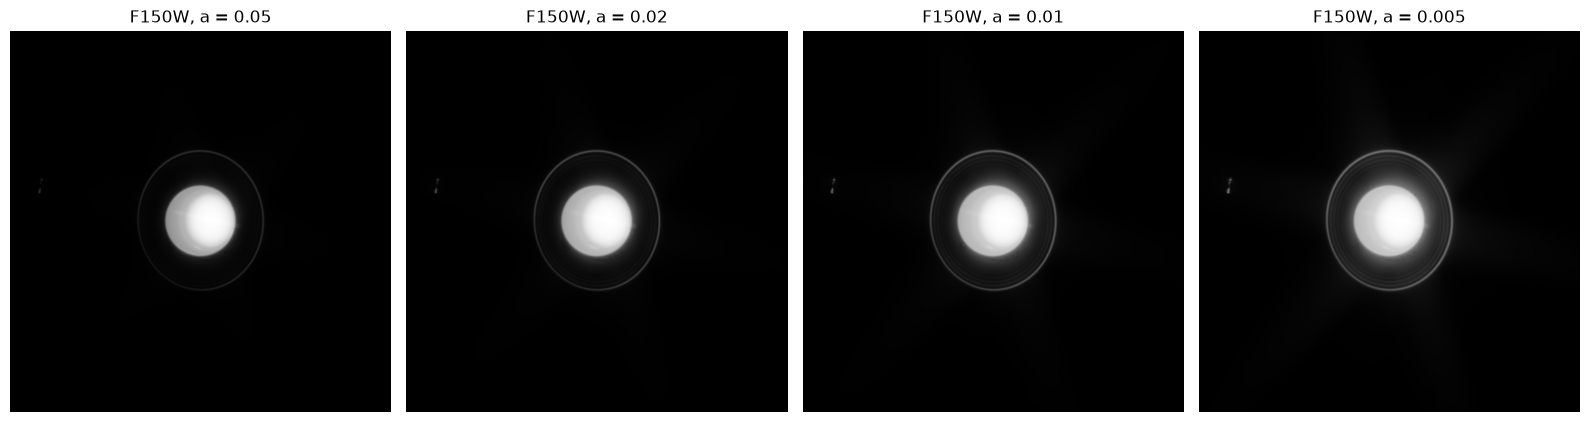

In [11]:
A_VALUES = [0.05, 0.02, 0.01, 0.005]
white = float(np.percentile((filled[SHARP] - stats[SHARP]["bkg"])[disk & valid], 99.5))
y, _, _ = stretch.normalize(filled[SHARP], valid, stats[SHARP]["bkg"], stats[SHARP]["noise"], 0.5, 99.9, white)
fig, axes = plt.subplots(1, len(A_VALUES), figsize=(16, 4.5))
for ax, a in zip(axes, A_VALUES):
    ax.imshow(stretch.asinh_stretch(y, a), origin="lower", cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{SHARP}, a = {a}")
    ax.axis("off")
plt.tight_layout()

**Checkpoint:** choose `A_VALUE`.

F115W: disk median after stretch 0.88
F150W: disk median after stretch 0.85
F277W: disk median after stretch 0.82
F356W: disk median after stretch 0.60
F444W: disk median after stretch 0.85


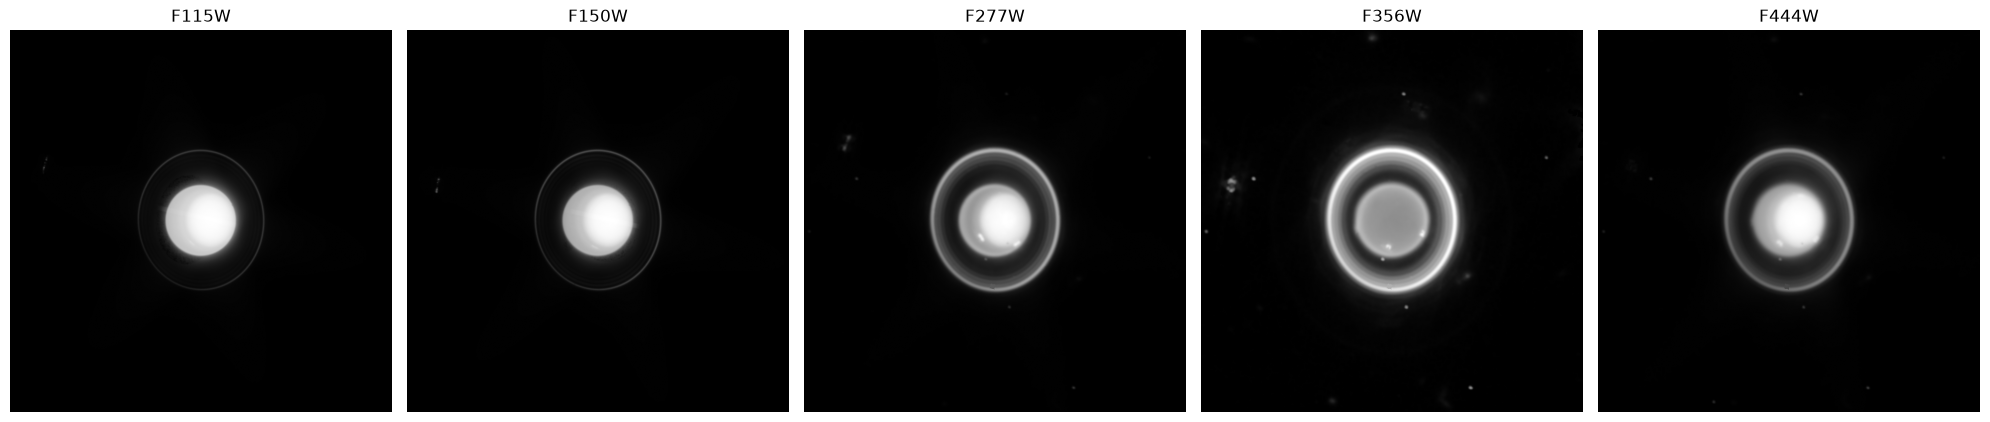

In [12]:
A_VALUE, BLACK_K, WHITE_PCT_DISK = 0.02, 0.5, 99.5
WHITE_FROM_FIELD = {"F356W": 99.95}   # dark disk, bright rings: white point from the brightest pixels of the field

params = {}
for b in filled:
    x = filled[b] - stats[b]["bkg"]
    white = (np.percentile(x[valid], WHITE_FROM_FIELD[b]) if b in WHITE_FROM_FIELD
             else np.percentile(x[disk & valid], WHITE_PCT_DISK))
    params[b] = dict(black_k=BLACK_K, white_pct=99.9, a=A_VALUE, white_value=float(white))
stretched, levels = stretch.stretch_all(filled, valid, stats, params)
if UNIFY_SATURATED:
    for b in stretched:
        stretched[b][sat_union] = 1.0

fig, axes = plt.subplots(1, len(stretched), figsize=(4 * len(stretched), 4.5))
for ax, b in zip(axes, stretched):
    ax.imshow(stretched[b], origin="lower", cmap="gray", vmin=0, vmax=1)
    ax.set_title(b)
    ax.axis("off")
plt.tight_layout()
for b in stretched:
    print(f"{b}: disk median after stretch {np.median(stretched[b][disk]):.2f}")

## 8. Colour

Start: **A – chromatic** (hue by wavelength), and A with luminance from the sharp filter. The disk medians printed above tell whether the filters differ on the disk (→ colour contrast) or not (→ the mix tends to the average hue, as for Neptune). Look for a filter that stands out (dark disk but bright features) – it is the lever for a freely chosen variant, as F300M was for Neptune.

**Checkpoint:** add own ideas to `VARIANTS` and choose what to export.

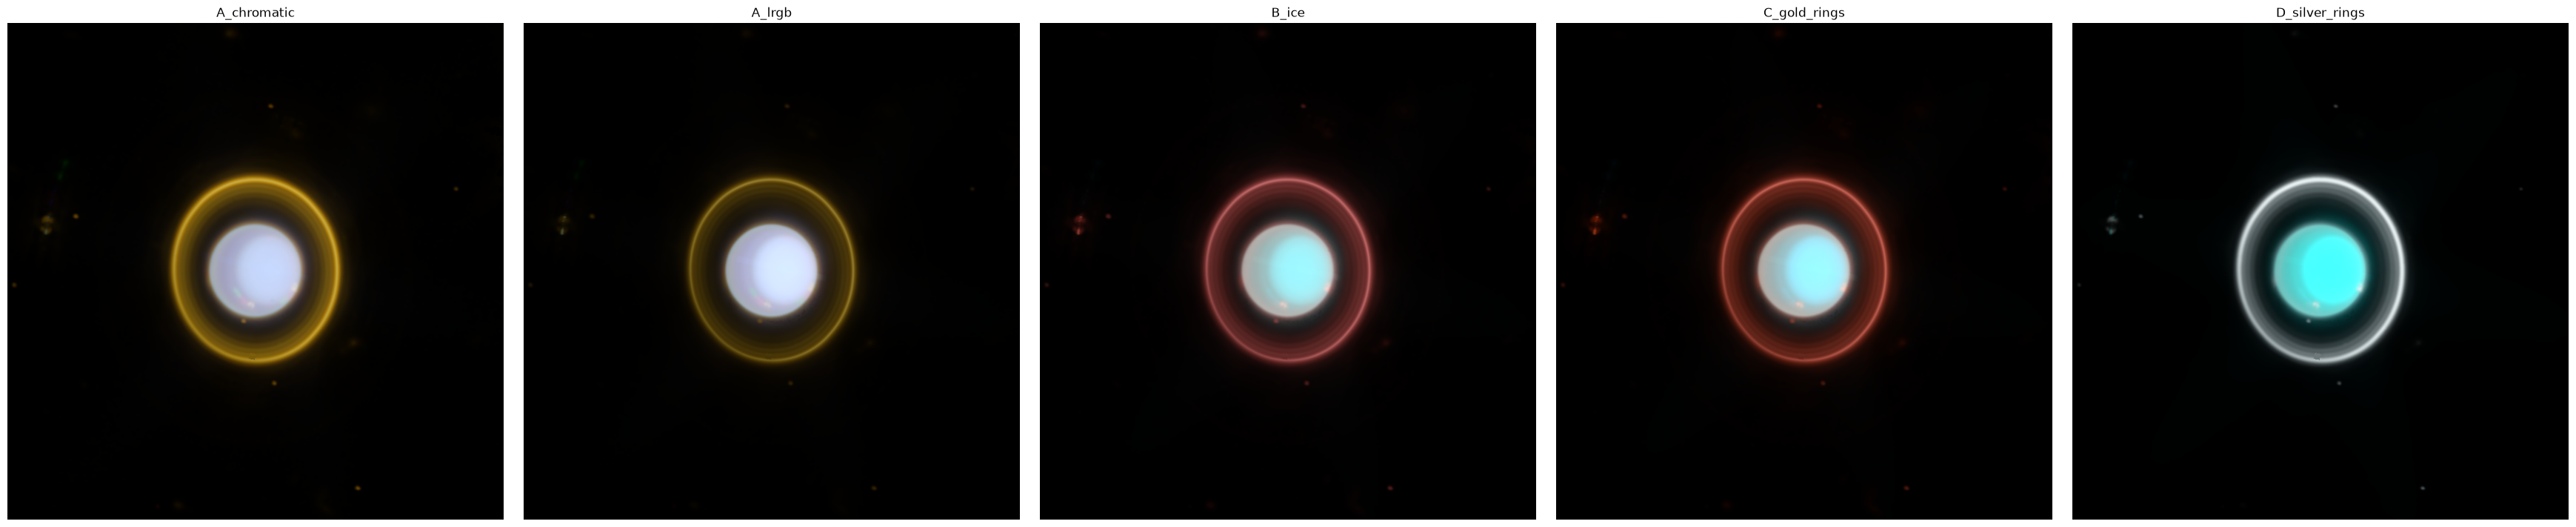

In [13]:
chromatic = {b: 240 - i * 240 / (len(stretched) - 1) for i, b in enumerate(stretched)}
LUM = {SHARP: stretched[SHARP]}

VARIANTS = {
    "A_chromatic": dict(hues=chromatic, label="hues by wavelength (chromatic)"),
    "A_lrgb": dict(hues=chromatic, lum=(SHARP, 0.5), label=f"chromatic, 50 % luminance from {SHARP}"),
    "B_ice": dict(
        hues={"F115W": 185, "F150W": 195, "F277W": 205, "F356W": 0, "F444W": 215}, sat={"F356W": 0.0},
        lum=(SHARP, 0.5),
        label="chosen freely, inspired by Uranus' visible-light colour: F356W without colour (rings silver-white)"),
    "C_gold_rings": dict(
        hues={"F115W": 185, "F150W": 195, "F277W": 205, "F356W": 40, "F444W": 215},
        lum=(SHARP, 0.5),
        label="chosen freely: cool disk, F356W gold (rings golden)"),
        "D_silver_rings": dict(
        hues={"F115W": 185, "F150W": 195, "F277W": 205, "F444W": 215},   # F356W not in the colour mix
        lum=(SHARP, 0.5), white_overlay=("F356W", 0.9),
        label="chosen freely: cool disk from four filters, F356W laid over as white light (rings silver)"),
}

def make_rgb(v):
    rgb = color.compose(stretched, color.mapping_from_degrees(v["hues"], v.get("sat", {})), v.get("weights", {}))
    if "lum" in v:
        rgb = color.apply_luminance(rgb, LUM[v["lum"][0]], v["lum"][1])
        if "white_overlay" in v:       # band added as white light where it is bright ("lighten" blend)
            band, k = v["white_overlay"]
            w = np.clip(k * stretched[band], 0, 1)[..., None]
            rgb = np.clip(rgb * (1 - w) + w * np.maximum(rgb, stretched[band][..., None]), 0, 1)
    return rgb


rgbs = {k: make_rgb(v) for k, v in VARIANTS.items()}
fig, axes = plt.subplots(1, len(rgbs), figsize=(7 * len(rgbs), 7), squeeze=False)
for ax, (k, rgb) in zip(axes[0], rgbs.items()):
    ax.imshow(rgb, origin="lower")
    ax.set_title(k)
    ax.axis("off")
plt.tight_layout()

## 9. Export

Chosen variants (`EXPORT`) as TIFF/PNG (full resolution, `output/full_res/`) and web JPEG + caption (`output/`); parameters to `params/uranus.json`.

In [14]:
EXPORT = ["A_chromatic", "D_silver_rings"]

north_up, east_left = export.orientation(wcs_out, n // 2, n // 2)
print("north up:", north_up, "  east left:", east_left)


def caption_for(name):
    v = VARIANTS[name]
    table = "\n".join(f"| {b} | {v['hues'][b]:.0f}°" + (" (no colour)" if v.get("sat", {}).get(b) == 0 else "")
                       + " |" for b in v["hues"])
    steps = ["calibrated stage-3 images (`_i2d.fits`) from MAST"]
    if EXCLUDE:
        steps.append(f"{', '.join(EXCLUDE)} not used (planet's disk saturated)")
    steps += ["row destriping on empty sky (no high-pass)" + (" + 2-D background (128 px)" if USE_BG2D else ""),
              "aligned on the planet (WCS shifted by the target's mean positions, header MT_AVRA/MT_AVDEC)",
              f"close-up grid {RES:.3f}″/px centred on {TARGET} (`reproject_adaptive`; long-wavelength filters upsampled ×2)",
              "background from empty corners",
              f"asinh stretch (a = {A_VALUE}), white point from the disk ({WHITE_PCT_DISK} %)"
              + (f", for {', '.join(WHITE_FROM_FIELD)} from the brightest field pixels (rings)" if WHITE_FROM_FIELD else "")
              + ", each filter normalised to its own white point",
              "additive colour mixing"
              + (f", {int(v['lum'][1] * 100)} % of the brightness from {v['lum'][0]} (LRGB)" if "lum" in v else "")
              + (f", {v['white_overlay'][0]} laid over as white light (strength {v['white_overlay'][1]})"
                 if "white_overlay" in v else ""),
              "bad pixels filled with the local median, saturated features with the local maximum"
              + (", white in all filters where saturated in any" if UNIFY_SATURATED else "") + "; no local adjustments"]
    return f"""# {TARGET} – JWST NIRCam

{TARGET}, observed on {DATE} with NIRCam on the James Webb Space Telescope (programme {PROGRAM}). Field of view ≈ {FIELD_ARCSEC:.0f}″ × {FIELD_ARCSEC:.0f}″, {"north up, east left" if (north_up and east_left) else "ORIENTATION TO BE CHECKED"}. Filters taken at slightly different times were aligned on the planet.

## Colour assignment ({name}: {v['label']})

| Filter | Hue |
|---|---|
{table}

The recorded light is infrared; all colours are an assignment, not "true" colours.

## Processing

{" → ".join(steps)}. Notebook `13_uranus.ipynb`; all values in `params/uranus.json`.

## Credits

Data: NASA, ESA, CSA, STScI (programme {PROGRAM}), retrieved via MAST. Processing: Tritium13.
"""


paths = {}
for name in EXPORT:
    paths[name] = export.save_outputs(rgbs[name], caption_for(name), f"{TARGET.lower()}_{name}",
                                      ROOT / "output/full_res", ROOT / "output")
    print(name, "->", [p.name for p in paths[name]])

json.dump({"files": {b: f.name for b, f in FILES.items()},
           "moving_target_shift_arcsec": {b: [o[0] * 3600, o[1] * 3600] for b, o in offs.items()},
           "grid": {"centre_radec": [ra0, dec0], "pixel_arcsec": RES, "size_px": n},
           "disk_centre_yx": {b: list(c) for b, c in cen.items()}, "use_bg2d": USE_BG2D,
           "unify_saturated": UNIFY_SATURATED, "sky_boxes": [list(map(int, bx)) for bx in boxes],
           "stretch": {b: {**params[b], **stats[b], **levels[b]} for b in params},
           "colour_variants": VARIANTS, "exported": EXPORT},
          open(ROOT / f"params/{TARGET.lower()}.json", "w"), indent=2, default=float)

north up: True   east left: True
A_chromatic -> ['uranus_A_chromatic_16bit.tif', 'uranus_A_chromatic_full.png', 'uranus_A_chromatic_web.jpg', 'uranus_A_chromatic_caption.md']
D_silver_rings -> ['uranus_D_silver_rings_16bit.tif', 'uranus_D_silver_rings_full.png', 'uranus_D_silver_rings_web.jpg', 'uranus_D_silver_rings_caption.md']


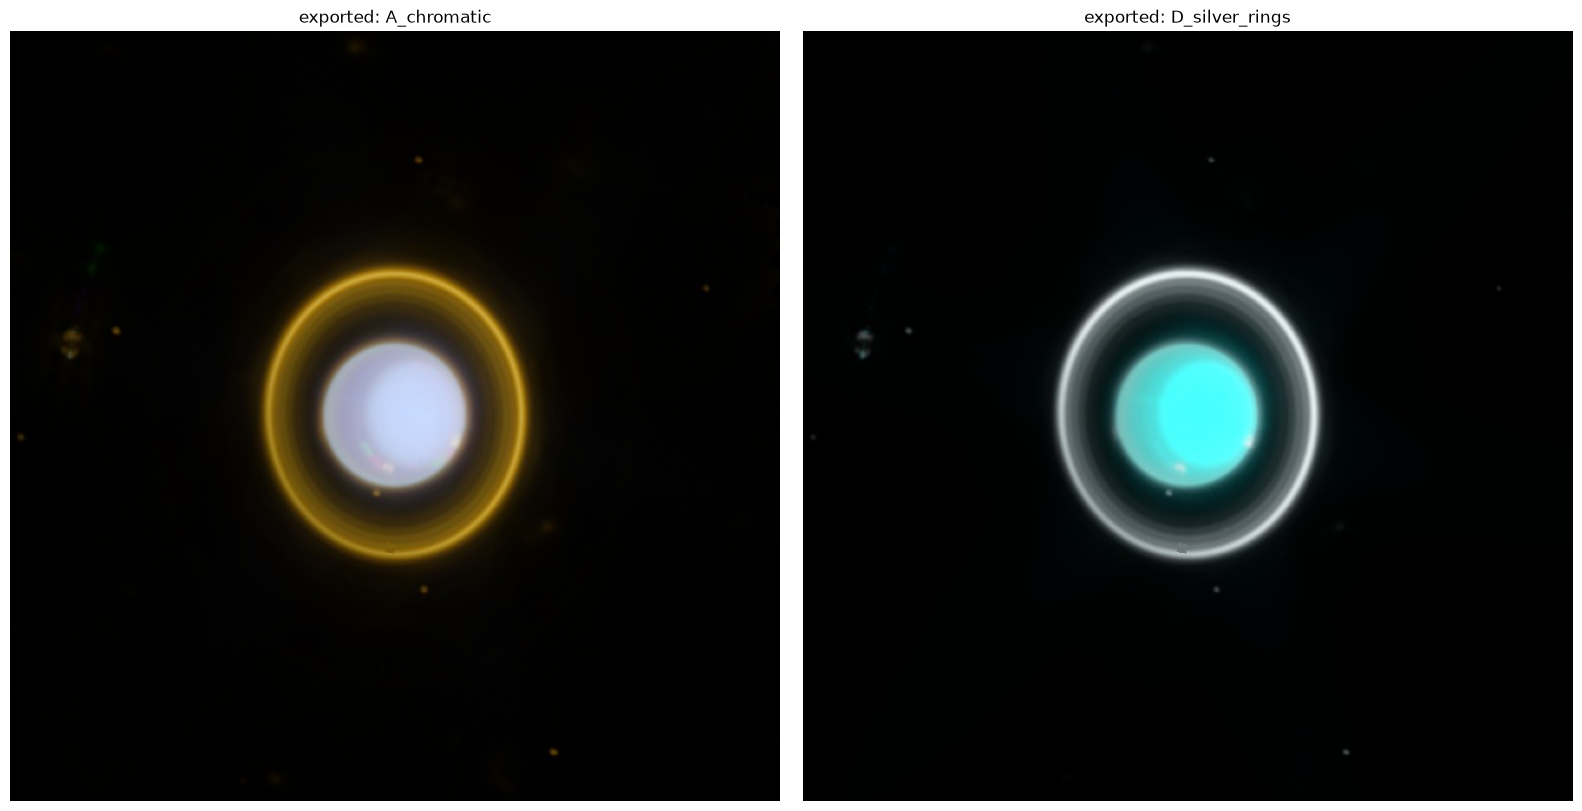

In [15]:
from PIL import Image
fig, axes = plt.subplots(1, len(EXPORT), figsize=(8 * len(EXPORT), 8), squeeze=False)
for ax, name in zip(axes[0], EXPORT):
    ax.imshow(Image.open(paths[name][2]))
    ax.set_title(f"exported: {name}")
    ax.axis("off")
plt.tight_layout()

## Conclusion

- **Reusing the planet workflow:** with all target values in one parameter cell, the Neptune workflow carried over to Uranus – but needed several target-specific decisions, which should become parameters of the template.
- **F070W:** the whole disk is saturated (all disk pixels NaN, ≈ 12 000 px in total) – too large to fill and without information → `EXCLUDE`.
- **Disk centre:** in F150W, F277W and F444W mainly the bright polar region (probably the north polar cap) shows, so the area centre lies off the disk centre. Reference for the disk: F115W (evenly lit). Alignment is confirmed by filters exposed at the same time (F115W↔F356W 1.7 px); the remaining offsets are the polar region, not a shift. A centre from the disk *edge* (circle fit) would be more robust.
- **2-D background:** removed the planet's outer halo (PSF wings) unevenly around the mask → not used for Uranus.
- **Stretch:** the large, bright disk turns almost white at a = 0.01 → a = 0.02. F356W (dark disk, bright rings) gets its white point from the brightest field pixels (the rings).
- **Colour:** chromatic order already gives golden rings (F356W/F444W). Giving F356W no colour (as F300M for Neptune) turned the rings **pink**: it was the only filter contributing red. Laying F356W over as white light ("lighten") instead makes the rings silver while the disk keeps its colour (D).
- **Open:** generalise the template (REF, EXCLUDE, WHITE_FROM_FIELD as parameters; edge-based disk centre); Jupiter next; then transfer to `run.py`.